In [1]:
words = open('names.txt', 'r').read().splitlines()

In [2]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
len(words)

32035

In [4]:
min(len(w) for w in words)

2

In [5]:
max(len(w) for w in words)

15

In [6]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1  # +1 is for the count of apperiance for each character 
        # print(ch1, ch2)

In [7]:
sorted(b.items(),key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3265),
 (('e', 'l'), 3248),
 (('r', 'i'), 3034),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1640),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [8]:
import torch

In [9]:
N = torch.zeros((27, 27), dtype = torch.int32) # using int as we are displayng counts

In [10]:
# character level Tokienization 
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)} # i+1 is basically doing a = 1 and not a = 0 since we have declared '.' = 0
stoi['.'] = 0 # implicitly assigning it
itos = {i:s for s,i in stoi.items()}

In [11]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1

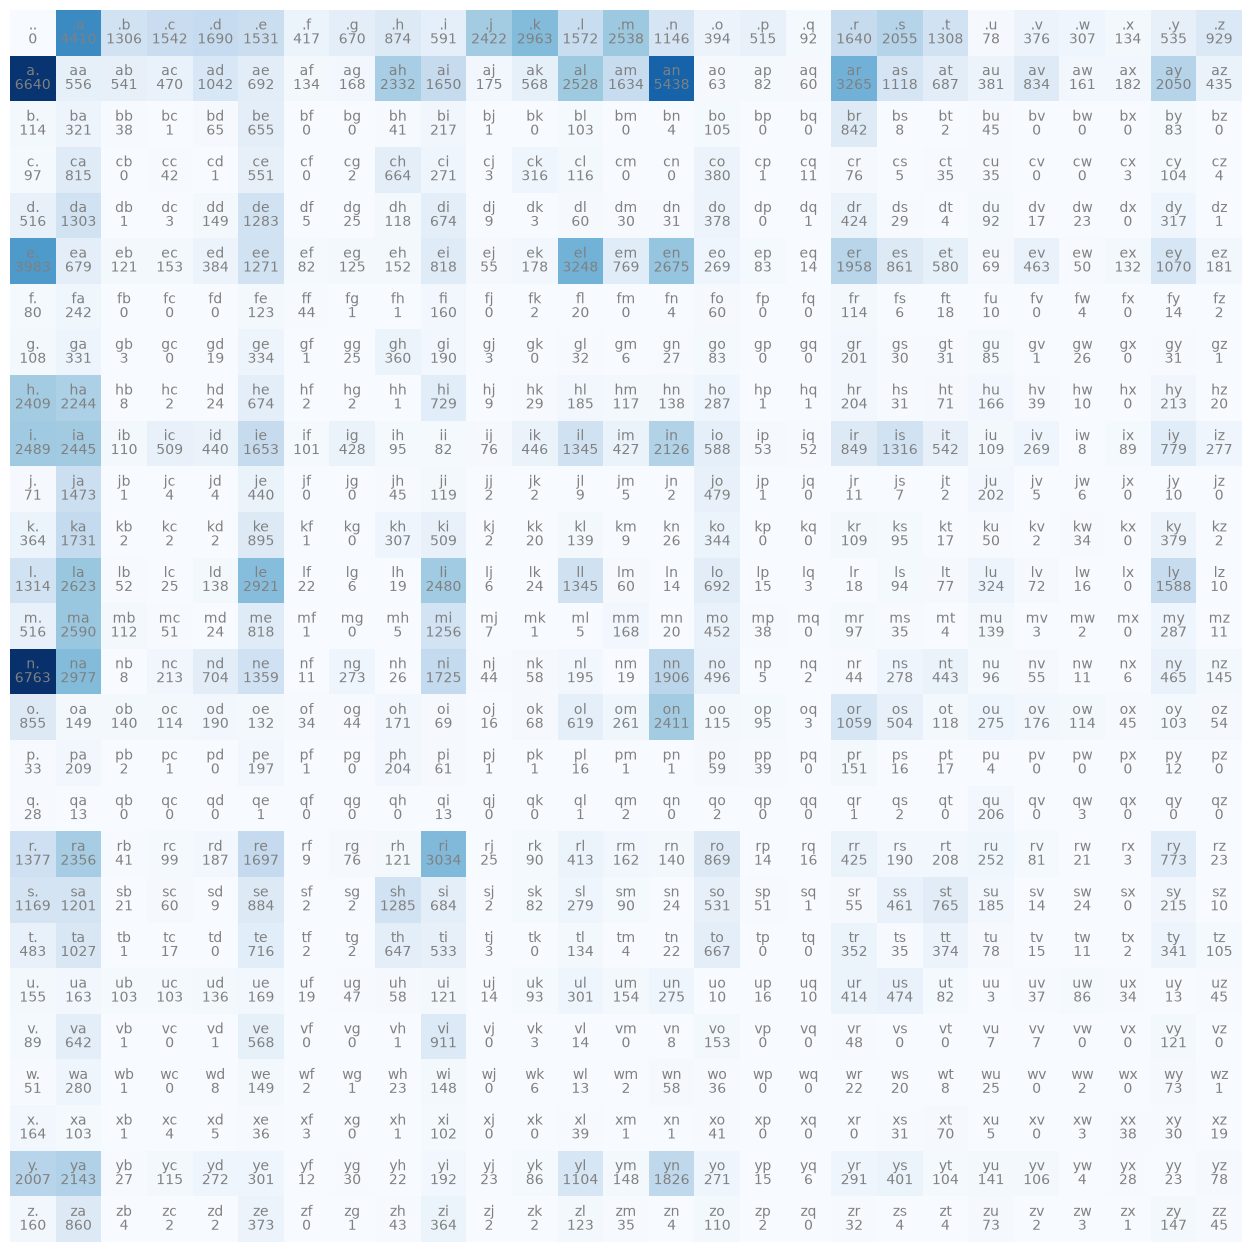

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [13]:
# using Generators for the same results everytime 
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g) # Generating 3 random numbers(0-1)
p = p / p.sum() # Normilization 
p

tensor([0.6064, 0.3033, 0.0903])

In [14]:
torch.multinomial(p, num_samples=100, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 1, 0,
        0, 1, 1, 1])

In [15]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  670,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1640, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [16]:
# Example of normalization
p = N[0].float()
p = p / p.sum()
p.shape

torch.Size([27])

In [17]:
# Making a Metrix with all the rows
P = (N + 1).float() # (N+1) is basically makin sure that prob of something happening cant be 0, the more the value the smoother the graph
P.shape

torch.Size([27, 27])

In [18]:
# adding the total sum of all the rows individually 
P.sum(1, keepdim=True).shape 

torch.Size([27, 1])

In [19]:
# BROADCASTING SEMANTICS 
# 27, 27
# 27, 1

In [20]:
# now Normalising the entire matrix
P /= P.sum(1, keepdim=True)

In [21]:
# Using the data set here
ix = torch.multinomial(p, num_samples=1, replacement=True).item()
itos[ix]

'e'

In [22]:
for i in range(20):
    out = []
    ix = 0

    while True:
        p = P[ix]
        # p = N[ix].float()
        # p = p / p.sum()
        # p = torch.ones(27) / 27.0

        ix = torch.multinomial(p, num_samples=1, replacement=True).item()
        out.append(itos[ix])

        if ix == 0:
            break

    print(''.join(out))

ppiamen.
on.
zy.
wiay.
a.
lymmen.
pricoralyn.
jumabiakylord.
ashrelaeli.
i.
son.
myndinalam.
mavaoshtidire.
a.
javannje.
ha.
lalineen.
tayi.
rimaira.
lyaa.


In [23]:
# GOAL: maximize likelihood of the data w.r.t. model parameters (statistical modeling)
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

# log(a*b*c) = log(a) + log(b) + log(c)

In [24]:
log_likelihood = 0.0 # simpler value to work with
n = 0 # this value is for the number of times the loop runs 


for w in words[:3]:
# for w in ['garv']:  # we can see the probability of basically any word
# for w in ['ritik']:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1, ix2] # Assigning the probability of every occurance
    logprob = torch.log(prob) # Log() the probability so we can deal with the probability better
    log_likelihood += logprob
    n += 1
    print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

      
print(f'{log_likelihood = }')
nll = -log_likelihood
print(f'{nll = }')
print(f'{nll/n}') # Making the AVG log_liklihood 
# if the probability of something is 0 ex jq so the log(0) be inf and thats an error here

.e: 0.0478 -3.0411
em: 0.0377 -3.2793
mm: 0.0253 -3.6753
ma: 0.3885 -0.9454
a.: 0.1958 -1.6305
.o: 0.0123 -4.3965
ol: 0.0779 -2.5526
li: 0.1774 -1.7293
iv: 0.0152 -4.1846
vi: 0.3506 -1.0480
ia: 0.1380 -1.9808
a.: 0.1958 -1.6305
.a: 0.1376 -1.9836
av: 0.0246 -3.7041
va: 0.2472 -1.3975
a.: 0.1958 -1.6305
log_likelihood = tensor(-38.8099)
nll = tensor(38.8099)
2.42561674118042


In [25]:
# creating the traning set of biagrams (x, y)
xs, ys = [], []

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    print(ch1, ch2)
    xs.append(ix1)
    ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

. e
e m
m m
m a
a .


In [26]:
xs

tensor([ 0,  5, 13, 13,  1])

In [27]:
ys

tensor([ 5, 13, 13,  1,  0])

In [28]:
# the raw index in the lists xs, ys cannot be feeded in the neural net as a input so we are making the vectors of these integers
import torch.nn.functional as F # one_hot is a type of vector  for integers in torch 
xenc = F.one_hot(xs,num_classes=27).float() # float() so that the values can be floating points 
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [29]:
xenc.shape

torch.Size([5, 27])

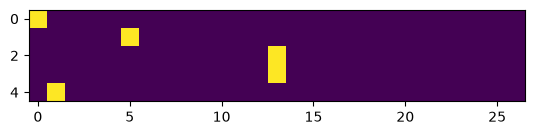

In [30]:
plt.imshow(xenc)

In [31]:
xenc.dtype

torch.float32

In [32]:
# initialising the weights for the neuron
W = torch.randn(27, 27, requires_grad=True) # this 'requires_grad=True' will tell the pytorch that we want to calculate the gradients 
xenc @ W  # Multiplying the Weights with the inputs, @ is matrix multiplication here

tensor([[ 0.5585, -1.4717,  0.7970, -0.3817, -1.0032,  1.0268, -0.5943,  0.8982,
          0.6341,  0.0798,  0.6689, -0.0101, -1.2382, -1.6017,  1.3642, -0.6418,
          1.1540,  1.2559,  0.9334,  0.0038,  0.4896,  1.1507,  0.0809, -0.4308,
         -1.9472,  0.8315,  1.2259],
        [-0.6265,  0.2621, -1.0200,  1.1682,  0.6147,  0.5838,  1.5283, -0.8651,
          0.4899,  1.2197,  0.5767,  0.9299, -0.1283,  0.3554, -2.7731, -0.1785,
         -0.3396, -0.9420,  0.4758,  0.8780,  0.6126,  1.0967,  0.2902,  0.1925,
          0.8649, -0.1162,  1.3631],
        [ 0.1164, -1.5088, -0.5456,  0.8482, -0.8569, -1.5131,  0.7383,  0.8982,
          0.0461,  1.2638, -2.6190, -0.8301, -0.0352,  1.2047, -1.1880, -1.3065,
         -2.2095, -0.5224,  0.3907, -0.4671, -1.8935, -0.9592,  1.0904, -0.1704,
          1.1426,  0.3138,  0.2446],
        [ 0.1164, -1.5088, -0.5456,  0.8482, -0.8569, -1.5131,  0.7383,  0.8982,
          0.0461,  1.2638, -2.6190, -0.8301, -0.0352,  1.2047, -1.1880, -1.3065

In [33]:
(xenc @ W).shape

torch.Size([5, 27])

In [34]:
# ([5, 27] @ [27, 27]) --> [5, 27]

In [35]:
# Forward Pass
logits = xenc @ W #log-Counts
counts = logits.exp() # Equivalent N
probs = counts / counts.sum(1, keepdims=True)
# The last two lines are working as a softmax fuction
print(probs)
# loss function here is basically the negative log_likelihood
loss = -probs[torch.arange(0, 5), ys].log().mean()

tensor([[0.0393, 0.0052, 0.0499, 0.0153, 0.0082, 0.0628, 0.0124, 0.0552, 0.0424,
         0.0243, 0.0439, 0.0223, 0.0065, 0.0045, 0.0879, 0.0118, 0.0713, 0.0789,
         0.0572, 0.0226, 0.0367, 0.0710, 0.0244, 0.0146, 0.0032, 0.0516, 0.0766],
        [0.0115, 0.0281, 0.0078, 0.0695, 0.0399, 0.0387, 0.0996, 0.0091, 0.0352,
         0.0731, 0.0384, 0.0547, 0.0190, 0.0308, 0.0013, 0.0181, 0.0154, 0.0084,
         0.0348, 0.0520, 0.0399, 0.0647, 0.0289, 0.0262, 0.0513, 0.0192, 0.0844],
        [0.0347, 0.0068, 0.0179, 0.0722, 0.0131, 0.0068, 0.0647, 0.0759, 0.0324,
         0.1093, 0.0023, 0.0135, 0.0298, 0.1031, 0.0094, 0.0084, 0.0034, 0.0183,
         0.0457, 0.0194, 0.0047, 0.0118, 0.0919, 0.0261, 0.0969, 0.0423, 0.0395],
        [0.0347, 0.0068, 0.0179, 0.0722, 0.0131, 0.0068, 0.0647, 0.0759, 0.0324,
         0.1093, 0.0023, 0.0135, 0.0298, 0.1031, 0.0094, 0.0084, 0.0034, 0.0183,
         0.0457, 0.0194, 0.0047, 0.0118, 0.0919, 0.0261, 0.0969, 0.0423, 0.0395],
        [0.0380, 0.1053,

In [36]:
probs[0]

tensor([0.0393, 0.0052, 0.0499, 0.0153, 0.0082, 0.0628, 0.0124, 0.0552, 0.0424,
        0.0243, 0.0439, 0.0223, 0.0065, 0.0045, 0.0879, 0.0118, 0.0713, 0.0789,
        0.0572, 0.0226, 0.0367, 0.0710, 0.0244, 0.0146, 0.0032, 0.0516, 0.0766],
       grad_fn=<SelectBackward0>)

In [37]:
probs[0].shape

torch.Size([27])

In [38]:
probs[0].sum()

tensor(1., grad_fn=<SumBackward0>)

In [39]:
print(loss.item())

3.355335235595703


In [40]:
# backward Pass
W.grad = None # set to zero the gradient, its better then manually putting 0, it works as lack of the gradient here 
loss.backward()

In [41]:
W.shape

torch.Size([27, 27])

In [42]:
W.grad.shape

torch.Size([27, 27])

In [43]:
W.data += -0.1 * W.grad # updating the weights 

In [44]:
print(loss.item())

3.355335235595703


In [45]:
# Below are Just arranged one cell codes of these upper notebooks for forward pass and backward pass los function that is gradient descent

# create the dataset
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement() # counts the number of elements in 'xs' so we can see the number of examples we are working with
print('number of examples: ', num)

# initialize the 'network'
W = torch.randn((27, 27), requires_grad=True)

number of examples:  228157


In [48]:
# gradient descent
for k in range(10000):
  
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts
  counts = logits.exp() # counts, equivalent to N
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()# 0.01*(W**2).mean() is bor regularization/making the prob distribution uniform
  print(loss.item())
  
  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()
  
  # update
  W.data += -100 * W.grad

3.1583619117736816
2.934115409851074
2.8178951740264893
2.7561333179473877
2.7089953422546387
2.697014331817627
2.654815673828125
2.6400537490844727
2.6184587478637695
2.6213083267211914
2.593808889389038
2.5919930934906006
2.579134225845337
2.589193105697632
2.5652284622192383
2.567953586578369
2.5583062171936035
2.571753740310669
2.5484979152679443
2.5529115200042725
2.545397996902466
2.5608572959899902
2.53771710395813
2.542679786682129
2.536897659301758
2.5537357330322266
2.530416250228882
2.5354440212249756
2.531015634536743
2.54886531829834
2.5252504348754883
2.5301592350006104
2.526750326156616
2.545349597930908
2.521458148956299
2.526211738586426
2.5235345363616943
2.5426769256591797
2.5185885429382324
2.5232186317443848
2.52104115486145
2.54056453704834
2.5163626670837402
2.5209200382232666
2.5190672874450684
2.538853168487549
2.5146000385284424
2.5191280841827393
2.5174827575683594
2.5374464988708496
2.5131802558898926
2.5177083015441895
2.5161945819854736
2.536280632019043
2

In [49]:
# finally, sample from the 'neural net' model

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

mensh.
hacoriea.
n.
an.
tryares.
